In [1]:
import pandas as pd
import numpy as np
import random as rn

In [ ]:
spotify = pd.read_csv('spotify_skz_counts_album.csv')
spotify.head()

In [ ]:
pace = spotify.groupby('bpm')

In [ ]:
pace.sum().sort_values('number_of_streams',ascending= False)

In [ ]:
pace.max()
# we try to return song with highest number of streams in each bpm_pace

In [ ]:
len(pace)

In [ ]:
spotify.groupby("bpm").size().max()

In [ ]:
spotify.groupby("album_name").first()

In [ ]:
spotify.groupby("release_year").nth(6)

In [ ]:
pace.get_group(65)

In [ ]:
pd.set_option('display.max_columns', None)
pace.describe()

In [ ]:
pace.nunique()

In [ ]:
# pace.agg()

In [ ]:
for group,data in pace : 
    print(group,data[data['number_of_streams']==data['number_of_streams'].max()])

In [ ]:
def alpha(group):
    return group['track_name'].str.startswith('A').sum()

In [ ]:
pace.apply(alpha)

In [ ]:
def rank_streams(group):
    group['rank_streams_number'] = group['number_of_streams'].rank(ascending=False)
    return group

In [ ]:
# pd.set_option('display.max_rows',None)
pace.apply(rank_streams)

In [ ]:
def rank_normalise (group): 
    group['rank_streams_normal']=(group['number_of_streams']-group['number_of_streams'].min())/(group['number_of_streams'].max()-group['number_of_streams'].min())
    return group

In [ ]:
pace.apply(rank_normalise)

In [ ]:
# groupby multiple columns
year_albumtype = spotify.groupby(['release_year','album_type'])
year_albumtype.size()

In [ ]:
year_albumtype['number_of_streams'].sum().sort_values(ascending=False).head(1)

In [ ]:
spotify.groupby(['album_type','track_name'])['total_time_played'].sum().reset_index().sort_values('total_time_played',ascending=False)

Concat

In [2]:
cars = pd.read_csv('Automobile_data.csv')
cars = cars.replace('alfa-romero','alfa-romeo')
cars

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romeo,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.4,23.0,106,4800,26,27,22470


In [52]:
convertible = cars[cars['body-style']=='convertible']
pd.concat([convertible, cars], ignore_index=False)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
72,3,142,mercedes-benz,gas,std,two,convertible,rwd,front,96.6,180.3,70.5,50.8,3685,ohcv,eight,234,mpfi,3.46,3.1,8.3,155,4750,16,18,35056
128,3,?,porsche,gas,std,two,convertible,rwd,rear,89.5,168.9,65.0,51.6,2800,ohcf,six,194,mpfi,3.74,2.9,9.5,207,5900,17,25,37028
172,2,134,toyota,gas,std,two,convertible,rwd,front,98.4,176.2,65.6,53.0,2975,ohc,four,146,mpfi,3.62,3.5,9.3,116,4800,24,30,17669
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,2952,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,55.5,3049,ohc,four,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3012,ohcv,six,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.4,23.0,106,4800,26,27,22470


# multi-index dataframe

In [ ]:
concat_convertible_tail = pd.concat([convertible,cars], keys= ['Convertible Only','All cars'])
concat_convertible_tail.loc[('Convertible Only',172)]

symboling                      2
normalized-losses            134
make                      toyota
fuel-type                    gas
aspiration                   std
num-of-doors                 two
body-style           convertible
drive-wheels                 rwd
engine-location            front
wheel-base                  98.4
length                     176.2
width                       65.6
height                      53.0
curb-weight                 2975
engine-type                  ohc
num-of-cylinders            four
engine-size                  146
fuel-system                 mpfi
bore                        3.62
stroke                       3.5
compression-ratio            9.3
horsepower                   116
peak-rpm                    4800
city-mpg                      24
highway-mpg                   30
price                      17669
Name: (Convertible Only, 172), dtype: object

In [ ]:
concat_convertible_tail.loc[('All cars', 100)]

In [ ]:
concat_convertible_tail_level0 = pd.concat([convertible,cars], keys= ['Convertible Only','All cars']).reset_index()
concat_convertible_tail_level0

In [ ]:
concat_convertible_tail.sort_index(ascending=[True,False])

symboling normalized-losses           make fuel-type  \
All cars         204         -1                95          volvo       gas   
                 203         -1                95          volvo    diesel   
                 202         -1                95          volvo       gas   
                 201         -1                95          volvo       gas   
                 200         -1                95          volvo       gas   
...                         ...               ...            ...       ...   
Convertible Only 172          2               134         toyota       gas   
                 128          3                 ?        porsche       gas   
                 72           3               142  mercedes-benz       gas   
                 1            3                 ?     alfa-romeo       gas   
                 0            3                 ?     alfa-romeo       gas   

                     aspiration num-of-doors   body-style drive-wheels  \
All cars         204      turbo         four        sedan          rwd   
                 203      turbo         four        sedan          rwd   
                 202        std         four        sedan          rwd   
                 201      turbo         four        sedan          rwd   
                 200        std         four        sedan          rwd   
...                         ...          ...          ...          ...   
Convertible Only 172        std          two  convertible          rwd   
                 128        std          two  convertible          rwd   
                 72         std          two  convertible          rwd   
                 1          std          two  convertible          rwd   
                 0          std          two  convertible          rwd   

                     engine-location  wheel-base  length  width  height  \
All cars         204           front       109.1   188.8   68.9    55.5   
                 203           front       109.1   188.8   68.9    55.5   
                 202           front       109.1   188.8   68.9    55.5   
                 201           front       109.1   188.8   68.8    55.5   
                 200           front       109.1   188.8   68.9    55.5   
...                              ...         ...     ...    ...     ...   
Convertible Only 172           front        98.4   176.2   65.6    53.0   
                 128            rear        89.5   168.9   65.0    51.6   
                 72            front        96.6   180.3   70.5    50.8   
                 1             front        88.6   168.8   64.1    48.8   
                 0             front        88.6   168.8   64.1    48.8   

                      curb-weight engine-type num-of-cylinders  engine-size  \
All cars         204         3062         ohc             four          141   
                 203         3217         ohc              six          145   
                 202         3012        ohcv              six          173   
                 201         3049         ohc             four          141   
                 200         2952         ohc             four          141   
...                           ...         ...              ...          ...   
Convertible Only 172         2975         ohc             four          146   
                 128         2800        ohcf              six          194   
                 72          3685        ohcv            eight          234   
                 1           2548        dohc             four          130   
                 0           2548        dohc             four          130   

                     fuel-system  bore stroke  compression-ratio horsepower  \
All cars         204        mpfi  3.78   3.15                9.5        114   
                 203         idi  3.01    3.4               23.0        106   
                 202        mpfi  3.58   2.87                8.8        134   
                 201        mp

In [55]:
concat_convertible_tail.sort_index(level=1, ascending= True)

symboling normalized-losses        make fuel-type  \
All cars         0            3                 ?  alfa-romeo       gas   
Convertible Only 0            3                 ?  alfa-romeo       gas   
All cars         1            3                 ?  alfa-romeo       gas   
Convertible Only 1            3                 ?  alfa-romeo       gas   
All cars         2            1                 ?  alfa-romeo       gas   
...                         ...               ...         ...       ...   
                 200         -1                95       volvo       gas   
                 201         -1                95       volvo       gas   
                 202         -1                95       volvo       gas   
                 203         -1                95       volvo    diesel   
                 204         -1                95       volvo       gas   

                     aspiration num-of-doors   body-style drive-wheels  \
All cars         0          std          two  convertible          rwd   
Convertible Only 0          std          two  convertible          rwd   
All cars         1          std          two  convertible          rwd   
Convertible Only 1          std          two  convertible          rwd   
All cars         2          std          two    hatchback          rwd   
...                         ...          ...          ...          ...   
                 200        std         four        sedan          rwd   
                 201      turbo         four        sedan          rwd   
                 202        std         four        sedan          rwd   
                 203      turbo         four        sedan          rwd   
                 204      turbo         four        sedan          rwd   

                     engine-location  wheel-base  length  width  height  \
All cars         0             front        88.6   168.8   64.1    48.8   
Convertible Only 0             front        88.6   168.8   64.1    48.8   
All cars         1             front        88.6   168.8   64.1    48.8   
Convertible Only 1             front        88.6   168.8   64.1    48.8   
All cars         2             front        94.5   171.2   65.5    52.4   
...                              ...         ...     ...    ...     ...   
                 200           front       109.1   188.8   68.9    55.5   
                 201           front       109.1   188.8   68.8    55.5   
                 202           front       109.1   188.8   68.9    55.5   
                 203           front       109.1   188.8   68.9    55.5   
                 204           front       109.1   188.8   68.9    55.5   

                      curb-weight engine-type num-of-cylinders  engine-size  \
All cars         0           2548        dohc             four          130   
Convertible Only 0           2548        dohc             four          130   
All cars         1           2548        dohc             four          130   
Convertible Only 1           2548        dohc             four          130   
All cars         2           2823        ohcv              six          152   
...                           ...         ...              ...          ...   
                 200         2952         ohc             four          141   
                 201         3049         ohc             four          141   
                 202         3012        ohcv              six          173   
                 203         3217         ohc              six          145   
                 204         3062         ohc             four          141   

                     fuel-system  bore stroke  compression-ratio horsepower  \
All cars         0          mpfi  3.47   2.68                9.0        111   
Convertible Only 0          mpfi  3.47   2.68                9.0        111   
All cars         1          mpfi  3.47   2.68                9.0        111   
Convertible Only 1          mpfi  3.47   2.68                9.0  

In [64]:
concat_convertible_tail.swaplevel()

,,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,Convertible Only,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,Convertible Only,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
72,Convertible Only,3,142,mercedes-benz,gas,std,two,convertible,rwd,front,96.6,180.3,70.5,50.8,3685,ohcv,eight,234,mpfi,3.46,3.1,8.3,155,4750,16,18,35056
128,Convertible Only,3,?,porsche,gas,std,two,convertible,rwd,rear,89.5,168.9,65.0,51.6,2800,ohcf,six,194,mpfi,3.74,2.9,9.5,207,5900,17,25,37028
172,Convertible Only,2,134,toyota,gas,std,two,convertible,rwd,front,98.4,176.2,65.6,53.0,2975,ohc,four,146,mpfi,3.62,3.5,9.3,116,4800,24,30,17669
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,All cars,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,2952,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,All cars,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,55.5,3049,ohc,four,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,All cars,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3012,ohcv,six,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,All cars,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.4,23.0,106,4800,26,27,22470


# Best drive-wheels


In [ ]:
horspower_series = cars[['body-style','drive-wheels','horsepower']]
horspower_series['horsepower']= horspower_series['horsepower'].str.replace('?','80')
horspower_series['horsepower']= horspower_series['horsepower'].astype(int)
result = horspower_series.groupby(['body-style','drive-wheels'])['horsepower'].mean().reset_index().sort_values('horsepower', ascending=False).drop_duplicates(subset='body-style',keep='first')
result.info()

,body-style,drive-wheels,horsepower
3,hardtop,rwd,152.714286
6,hatchback,rwd,141.526316
1,convertible,rwd,140.000000
9,sedan,rwd,129.222222
12,wagon,rwd,116.777778


In [66]:
price_series = cars[['body-style','drive-wheels','price']]
price_series['price']= price_series['price'].str.replace('?','80')
price_series['price']= price_series['price'].astype(float)
price_mean = price_series.groupby(['body-style','drive-wheels'])['price'].mean().reset_index().sort_values('price', ascending=False).drop_duplicates(subset='body-style',keep='first')
price_mean.transpose()

,3,1,9,12,6
body-style,hardtop,convertible,sedan,wagon,hatchback
drive-wheels,rwd,rwd,rwd,rwd,rwd
price,24202.714286,23949.6,21711.833333,16994.222222,13587.368421


In [69]:
# melt
price_mean.melt(var_name="caracteristics", value_name='value')

,caracteristics,value
0,body-style,hardtop
1,body-style,convertible
2,body-style,sedan
3,body-style,wagon
4,body-style,hatchback
5,drive-wheels,rwd
6,drive-wheels,rwd
7,drive-wheels,rwd
8,drive-wheels,rwd
9,drive-wheels,rwd


In [70]:
price_mean.melt(id_vars='body-style')

,body-style,variable,value
0,hardtop,drive-wheels,rwd
1,convertible,drive-wheels,rwd
2,sedan,drive-wheels,rwd
3,wagon,drive-wheels,rwd
4,hatchback,drive-wheels,rwd
5,hardtop,price,24202.714286
6,convertible,price,23949.6
7,sedan,price,21711.833333
8,wagon,price,16994.222222
9,hatchback,price,13587.368421


In [ ]:
dimensions = cars[['make','fuel-type','length','width','height','price']]
dimensions.melt(id_vars=['make','fuel-type'])

,make,fuel-type,variable,value
0,alfa-romeo,gas,length,168.8
1,alfa-romeo,gas,length,168.8
2,alfa-romeo,gas,length,171.2
3,audi,gas,length,176.6
4,audi,gas,length,176.6
...,...,...,...,...
815,volvo,gas,price,16845
816,volvo,gas,price,19045
817,volvo,gas,price,21485
818,volvo,diesel,price,22470


In [85]:
length_series = cars[['body-style','drive-wheels','length']]
# length_series['length']= length_series['length'].str.replace('?','80')
# length_series['length']= length_series['length'].astype(int)
length = length_series.groupby(['body-style','drive-wheels'])['length'].mean().reset_index().sort_values('length', ascending=False).drop_duplicates(subset='body-style',keep='first')
length

,body-style,drive-wheels,length
12,wagon,rwd,193.411111
9,sedan,rwd,187.063889
3,hardtop,rwd,179.014286
6,hatchback,rwd,173.300000
1,convertible,rwd,172.600000


In [86]:
# concat side to side 
list_top_speed = []
rn.seed(1)
for i in range (0,205):
    list_top_speed.append(rn.randint(120,180))
# to dataframe
top_speed = pd.DataFrame()
top_speed['top_speed']= pd.Series(list_top_speed)
top_speed
# concat
fast = pd.concat([cars,top_speed], axis = 1)
pd.set_option('display.max_column',None)
fast

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,top_speed
0,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495,128
1,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500,156
2,1,?,alfa-romeo,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500,174
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950,171
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450,168
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,2952,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845,146
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,55.5,3049,ohc,four,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045,151
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3012,ohcv,six,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485,172
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.4,23.0,106,4800,26,27,22470,142


In [87]:
# merge

series_make = pd.Series(cars['make'].unique())
# 
list_make = series_make.to_list()
list_make
rn.seed(34)
make_choices = rn.choices(list_make, k=100)
make_choices
# 
make = pd.DataFrame()
make['make'] = pd.Series(make_choices)
make ['top_speed'] = pd.Series(rn.choices(range(120,180), k=100))
make

,make,top_speed
0,mitsubishi,147
1,nissan,155
2,subaru,167
3,toyota,135
4,toyota,165
...,...,...
95,volvo,146
96,mazda,130
97,saab,171
98,volvo,154


In [88]:
cars.merge(make, how = 'inner', on = 'make')

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,top_speed
0,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950,128
1,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950,143
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950,137
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950,123
4,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950,177
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1014,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625,146
1015,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625,160
1016,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625,150
1017,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625,146


In [89]:
cars.merge(make, how='right',on="make")

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,top_speed
0,2,161,mitsubishi,gas,std,two,hatchback,fwd,front,93.7,157.3,64.4,50.8,1918,ohc,four,92,2bbl,2.97,3.23,9.4,68,5500,37,41,5389,147
1,2,161,mitsubishi,gas,std,two,hatchback,fwd,front,93.7,157.3,64.4,50.8,1944,ohc,four,92,2bbl,2.97,3.23,9.4,68,5500,31,38,6189,147
2,2,161,mitsubishi,gas,std,two,hatchback,fwd,front,93.7,157.3,64.4,50.8,2004,ohc,four,92,2bbl,2.97,3.23,9.4,68,5500,31,38,6669,147
3,1,161,mitsubishi,gas,turbo,two,hatchback,fwd,front,93.0,157.3,63.8,50.8,2145,ohc,four,98,spdi,3.03,3.39,7.6,102,5500,24,30,7689,147
4,3,153,mitsubishi,gas,turbo,two,hatchback,fwd,front,96.3,173.0,65.4,49.4,2370,ohc,four,110,spdi,3.17,3.46,7.5,116,5500,23,30,9959,147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1014,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.4,23.0,106,4800,26,27,22470,154
1015,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625,154
1016,2,121,chevrolet,gas,std,two,hatchback,fwd,front,88.4,141.1,60.3,53.2,1488,l,three,61,2bbl,2.91,3.03,9.5,48,5100,47,53,5151,135
1017,1,98,chevrolet,gas,std,two,hatchback,fwd,front,94.5,155.9,63.6,52.0,1874,ohc,four,90,2bbl,3.03,3.11,9.6,70,5400,38,43,6295,135


In [90]:
cars.merge(make, how='outer', on ='make')

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,top_speed
0,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495,NaN
1,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500,NaN
2,1,?,alfa-romeo,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500,NaN
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950,128.0
4,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950,143.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625,146.0
1018,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625,160.0
1019,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625,150.0
1020,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625,146.0


In [91]:
engine = cars.groupby('body-style')['engine-size'].sum()

In [92]:
count = cars.groupby('body-style')['body-style'].count()

<Axes: xlabel='body-style'>

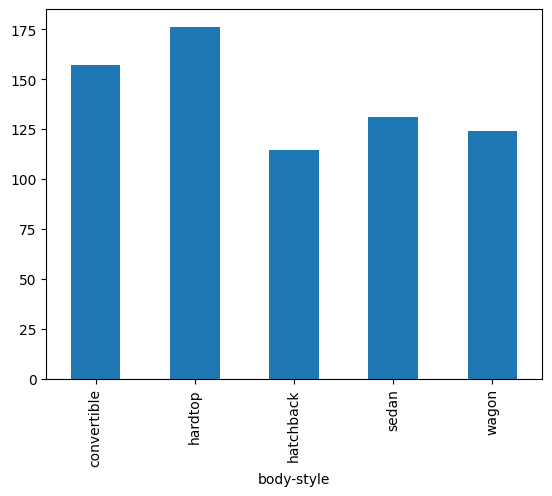

In [81]:
engine_size = pd.concat([engine,count], axis=1)
engine_size['ratio']= engine_size['engine-size'] / engine_size['body-style']

engine_size['ratio'].plot(kind ='bar')

In [82]:
equal_speed = np.intersect1d(fast['top_speed'], make['top_speed'])

In [83]:
fast[~fast['top_speed'].isin(equal_speed)]

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,top_speed
2,1,?,alfa-romeo,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500,174
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450,168
5,2,?,audi,gas,std,two,sedan,fwd,front,99.8,177.3,66.3,53.1,2507,ohc,five,136,mpfi,3.19,3.4,8.5,110,5500,19,25,15250,124
9,0,?,audi,gas,turbo,two,hatchback,4wd,front,99.5,178.2,67.9,52.0,3053,ohc,five,131,mpfi,3.13,3.4,7.0,160,5500,16,22,?,168
10,2,192,bmw,gas,std,two,sedan,rwd,front,101.2,176.8,64.8,54.3,2395,ohc,four,108,mpfi,3.5,2.8,8.8,101,5800,23,29,16430,148
24,1,148,dodge,gas,std,four,hatchback,fwd,front,93.7,157.3,63.8,50.6,1967,ohc,four,90,2bbl,2.97,3.23,9.4,68,5500,31,38,6229,168
26,1,148,dodge,gas,std,four,sedan,fwd,front,93.7,157.3,63.8,50.6,1989,ohc,four,90,2bbl,2.97,3.23,9.4,68,5500,31,38,7609,120
28,-1,110,dodge,gas,std,four,wagon,fwd,front,103.3,174.6,64.6,59.8,2535,ohc,four,122,2bbl,3.34,3.46,8.5,88,5000,24,30,8921,148
34,1,101,honda,gas,std,two,hatchback,fwd,front,93.7,150.0,64.0,52.6,1956,ohc,four,92,1bbl,2.91,3.41,9.2,76,6000,30,34,7129,180
43,0,?,isuzu,gas,std,four,sedan,rwd,front,94.3,170.7,61.8,53.5,2337,ohc,four,111,2bbl,3.31,3.23,8.5,78,4800,24,29,6785,120


In [84]:
fast.merge(fast, how ='inner', left_on='engine-size', right_on='top_speed')
# self join 

,symboling_x,normalized-losses_x,make_x,fuel-type_x,aspiration_x,num-of-doors_x,body-style_x,drive-wheels_x,engine-location_x,wheel-base_x,length_x,width_x,height_x,curb-weight_x,engine-type_x,num-of-cylinders_x,engine-size_x,fuel-system_x,bore_x,stroke_x,compression-ratio_x,horsepower_x,peak-rpm_x,city-mpg_x,highway-mpg_x,price_x,top_speed_x,symboling_y,normalized-losses_y,make_y,fuel-type_y,aspiration_y,num-of-doors_y,body-style_y,drive-wheels_y,engine-location_y,wheel-base_y,length_y,width_y,height_y,curb-weight_y,engine-type_y,num-of-cylinders_y,engine-size_y,fuel-system_y,bore_y,stroke_y,compression-ratio_y,horsepower_y,peak-rpm_y,city-mpg_y,highway-mpg_y,price_y,top_speed_y
0,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495,128,0,?,renault,gas,std,four,wagon,fwd,front,96.1,181.5,66.5,55.2,2579,ohc,four,132,mpfi,3.46,3.9,8.7,?,?,23,31,9295,130
1,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495,128,0,85,subaru,gas,std,four,wagon,4wd,front,96.9,173.6,65.4,54.9,2420,ohcf,four,108,2bbl,3.62,2.64,9.0,82,4800,23,29,8013,130
2,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495,128,0,85,subaru,gas,turbo,four,wagon,4wd,front,96.9,173.6,65.4,54.9,2650,ohcf,four,108,mpfi,3.62,2.64,7.7,111,4800,23,23,11694,130
3,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500,156,0,?,renault,gas,std,four,wagon,fwd,front,96.1,181.5,66.5,55.2,2579,ohc,four,132,mpfi,3.46,3.9,8.7,?,?,23,31,9295,130
4,3,?,alfa-romeo,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500,156,0,85,subaru,gas,std,four,wagon,4wd,front,96.9,173.6,65.4,54.9,2420,ohcf,four,108,2bbl,3.62,2.64,9.0,82,4800,23,29,8013,130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.4,23.0,106,4800,26,27,22470,142,0,161,peugot,diesel,turbo,four,sedan,rwd,front,107.9,186.7,68.4,56.7,3252,l,four,152,idi,3.7,3.52,21.0,95,4150,28,33,16900,145
270,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.4,23.0,106,4800,26,27,22470,142,2,104,saab,gas,std,four,sedan,fwd,front,99.1,186.6,66.5,56.1,2695,ohc,four,121,mpfi,3.54,3.07,9.3,110,5250,21,28,12170,145
271,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.4,23.0,106,4800,26,27,22470,142,0,89,subaru,gas,std,four,wagon,fwd,front,97.0,173.5,65.4,53.0,2290,ohcf,four,108,2bbl,3.62,2.64,9.0,82,4800,28,32,7463,145
272,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.4,23.0,106,4800,26,27,22470,142,0,91,toyota,gas,std,four,sedan,fwd,front,95.7,166.3,64.4,53.0,2094,ohc,four,98,2bbl,3.19,3.03,9.0,70,4800,38,47,7738,145
